# Triplet TORP on individual-RP RQA vectors

Closeness = similar dynamics. Each series gets one RQA feature vector per sliding window, and
$T_{ijk} = d(f^a_i, f^b_j) + d(f^a_i, f^c_k) + d(f^b_j, f^c_k)$.
Small $T_{www}$: in window w the three series have the same kind of dynamics. RR is dropped: ε is set by
the recurrence rate, so it is the same in every window.

## 1. Setup

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.rqa import rqa
from recplay.recurrence import threshold_by_rate
from recplay.torp import perimeter_tensor, same_time_stats, whitening_matrix
from recplay.windowed import euclidean_distance, rqa_frame, window_z

PRICES = Path("../../data/raw/yahoo/triplet_prices_2015_2024.csv")
OUT = Path("../tables/torp_rqa_individual")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

M, TAU, THEILER = 3, 1, 1      # same embedding as 01_triplet_perimeter
W, STEP = 250, 10              # one trading year per window, a new window every two weeks
RR_SERIES = 0.15               # per-series rate; joint RPs of independent series then recur at ~2.25 %
RR_TENSOR = 0.05               # fixed rate over all entries of the TORP
COVERAGE_MIN = 0.95            # a feature defined in fewer windows than this is dropped

FEATURES = ["DET", "L", "ENTR", "LAM", "K2_lines"]

TRIPLETS = {
    "none":            ("TIP", "UNG", "XLP"),
    "mid +":           ("FXY", "GLD", "TIP"),
    "mid + (risk)":    ("EWZ", "FXI", "HYG"),
    "high +":          ("EFA", "IWM", "SPY"),
    "one-out +":       ("GLD", "SLV", "UNG"),
    "mid mixed-sign":  ("XLE", "XLP", "^VIX"),
    "high mixed-sign": ("IWM", "SPY", "^VIX"),
    "one-out −":       ("EFA", "UNG", "^VIX"),
}
TICKERS = sorted({t for tr in TRIPLETS.values() for t in tr})

## 2. Data

In [2]:
if not PRICES.exists():
    raise FileNotFoundError(f"{PRICES} is written by 01_triplet_perimeter; run that notebook first")
prices = pd.read_csv(PRICES, index_col=0, parse_dates=True)
returns = np.log(prices).diff().iloc[1:].dropna()
full_r = returns.corr()

def triplet_pairs(tr):
    return [(tr[0], tr[1]), (tr[0], tr[2]), (tr[1], tr[2])]

pattern = pd.DataFrame({name: {"mean_r": np.mean([full_r.loc[p] for p in triplet_pairs(tr)]),
                               "mean_abs_r": np.mean([abs(full_r.loc[p]) for p in triplet_pairs(tr)]),
                               "abs_r_spread": np.ptp([abs(full_r.loc[p]) for p in triplet_pairs(tr)])}
                        for name, tr in TRIPLETS.items()}).T
print(f"{len(returns)} daily returns, {returns.index[0].date()} to {returns.index[-1].date()}")
pattern.round(2)

2515 daily returns, 2015-01-05 to 2024-12-31


,mean_r,mean_abs_r,abs_r_spread
none,0.03,0.03,0.03
mid +,0.41,0.41,0.09
mid + (risk),0.48,0.48,0.08
high +,0.84,0.84,0.07
one-out +,0.27,0.27,0.77
mid mixed-sign,-0.18,0.46,0.08
high mixed-sign,-0.17,0.75,0.22
one-out −,-0.21,0.27,0.60


## 3. Windowed RQA

In [3]:
series = {t: t for t in TICKERS}
frame = rqa_frame(returns, series, {}, W, M, TAU, RR_SERIES, euclidean_distance, THEILER, step=STEP)
rr_sd = max(frame[f"{t}_RR"].std() for t in TICKERS)
assert rr_sd < 1e-3, rr_sd     # ε comes from the target rate, so RR carries no information
vectors = {t: frame[[f"{t}_{k}" for k in FEATURES]].set_axis(FEATURES, axis=1) for t in TICKERS}
print(f"{len(frame)} windows ending {frame.index[0].date()} to {frame.index[-1].date()}, {len(TICKERS)} series; max RR std {rr_sd:.1e}")

227 windows ending 2015-12-30 to 2024-12-23, 14 series; max RR std 0.0e+00


## 4. Sign invariance check

In [4]:
x = returns["SPY"].to_numpy()
end = W - 1
plus = rqa(threshold_by_rate(euclidean_distance(window_z(x, end, W), M, TAU), RR_SERIES, THEILER))
minus = rqa(threshold_by_rate(euclidean_distance(window_z(-x, end, W), M, TAU), RR_SERIES, THEILER))
assert all(np.isclose(plus[k], minus[k], equal_nan=True) for k in plus)
print("RQA of x and -x agree: the features cannot see the sign of a series, so VIX needs no flip")

RQA of x and -x agree: the features cannot see the sign of a series, so VIX needs no flip


## 5. Normalisation and whitening

In [5]:
def prepare(vecs, label):
    """Pooled coverage rule, median fill, pooled z-score and whitening over every window of every key."""
    pooled = pd.concat(vecs.values())
    coverage = pooled.notna().mean()
    keep = [f for f in FEATURES if coverage[f] >= COVERAGE_MIN]
    filled = {k: v[keep].fillna(pooled[keep].median()) for k, v in vecs.items()}
    pooled = pd.concat(filled.values())
    mu, sd = pooled.mean(), pooled.std()
    z = {k: ((v - mu) / sd).to_numpy() for k, v in filled.items()}
    Wm = whitening_matrix(np.vstack(list(z.values())))
    info = {"set": label, "kept": ", ".join(keep), "dropped": ", ".join(f for f in FEATURES if f not in keep) or "none",
            "filled cells": int(sum(v[keep].isna().sum().sum() for v in vecs.values())),
            **{f"coverage {f}": coverage[f] for f in FEATURES}}
    return {"z": z, "white": {k: v @ Wm for k, v in z.items()}, "corr": pooled.corr(), "info": info}

In [6]:
sets = {"individual": prepare(vectors, "individual")}
display(pd.DataFrame([s["info"] for s in sets.values()]).set_index("set").round(3))
sets["individual"]["corr"].round(2)

,kept,dropped,filled cells,coverage DET,coverage L,coverage ENTR,coverage LAM,coverage K2_lines
set,,,,,,,,
individual,"DET, L, ENTR, LAM, K2_lines",none,0,1.0,1.0,1.0,1.0,1.0


,DET,L,ENTR,LAM,K2_lines
DET,1.00,0.83,0.84,0.72,-0.81
L,0.83,1.00,0.99,0.76,-0.94
ENTR,0.84,0.99,1.00,0.77,-0.96
LAM,0.72,0.76,0.77,1.00,-0.75
K2_lines,-0.81,-0.94,-0.96,-0.75,1.00


## 6. TORP per triplet

In [7]:
VARIANTS = {"mahalanobis": ("individual", "white"), "euclidean": ("individual", "z")}
def keys_of(tr):
    return list(tr)

In [8]:
rows, diagonals = [], {}
for name, tr in TRIPLETS.items():
    for variant, (set_name, kind) in VARIANTS.items():
        states = [sets[set_name][kind][k] for k in keys_of(tr)]
        T = perimeter_tensor(*states)
        idx = np.arange(len(T))
        diagonals[(name, variant)] = T[idx, idx, idx] / T.mean(dtype=np.float64)
        rows.append({"category": name, "variant": variant, "a": tr[0], "b": tr[1], "c": tr[2], **pattern.loc[name].to_dict(),
                     **same_time_stats(T, RR_TENSOR)})
        del T
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "summary.csv", index=False)
pd.DataFrame({f"{n} | {v}": d for (n, v), d in diagonals.items()}, index=frame.index).to_csv(OUT / "same_window_dissimilarity.csv")
summary.pivot(index="category", columns="variant", values=["sync_ratio", "sync_enrichment"]).loc[list(TRIPLETS)].round(3)

sync_ratio             sync_enrichment            
variant          euclidean mahalanobis       euclidean mahalanobis
category                                                          
none                 0.964       1.017           2.291       2.467
mid +                0.874       0.917           0.969       0.793
mid + (risk)         0.889       0.943           1.762       1.410
high +               0.624       0.802           2.996       2.819
one-out +            0.912       0.951           1.498       1.762
mid mixed-sign       0.768       0.884           1.938       2.203
high mixed-sign      0.727       0.828           2.555       3.524
one-out −            0.922       0.940           1.322       1.410

## 7. Relation to the correlation pattern

In [9]:
rel = []
for variant, g in summary.groupby("variant", sort=False):
    for col in ["mean_r", "mean_abs_r", "abs_r_spread"]:
        rel.append({"variant": variant, "against": col, "spearman (n = 8 triplets)": spearmanr(g[col], g["sync_ratio"]).statistic})
rel = pd.DataFrame(rel)
rel.to_csv(OUT / "relation_to_correlation.csv", index=False)
rel.pivot(index="variant", columns="against", values="spearman (n = 8 triplets)").round(2)

against,abs_r_spread,mean_abs_r,mean_r
variant,,,
euclidean,0.10,-0.93,-0.33
mahalanobis,0.02,-0.81,-0.10


## 8. Figures

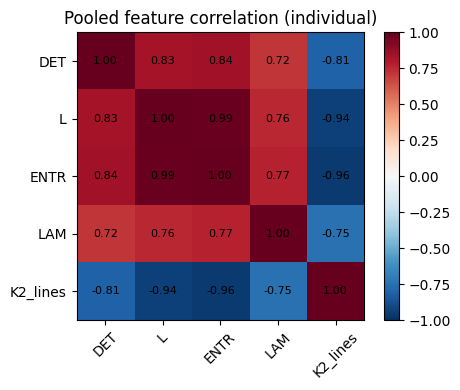

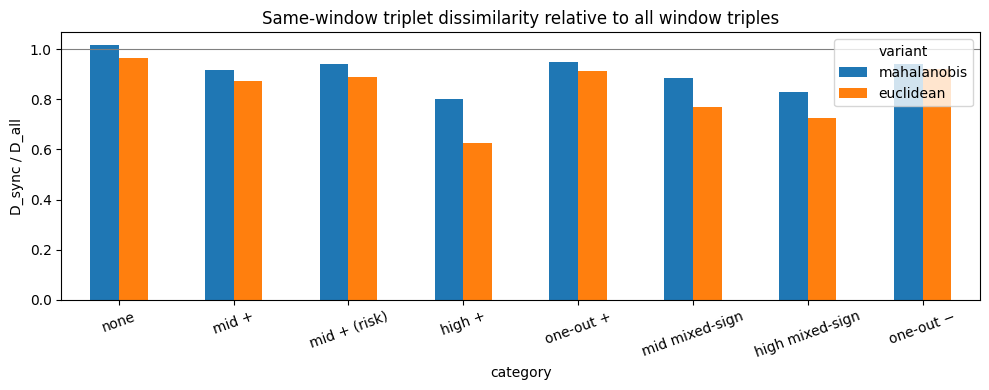

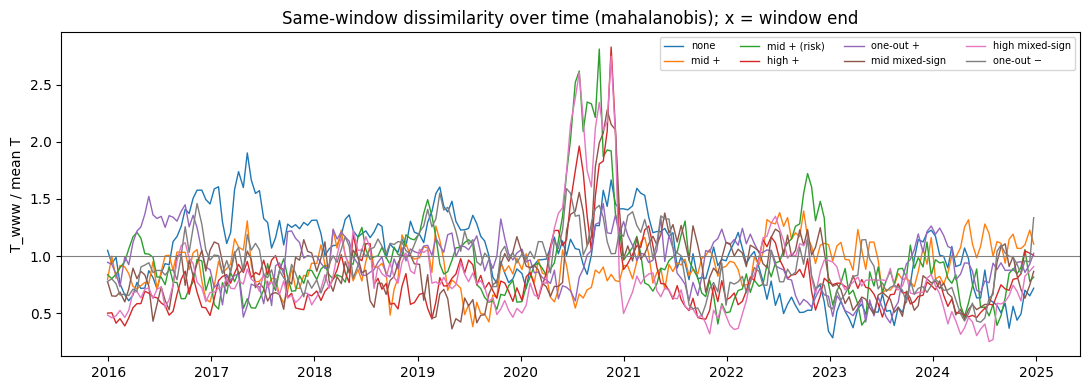

In [10]:
first = next(iter(sets.values()))
fig, ax = plt.subplots(figsize=(5, 4))
c = first["corr"]
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=45); ax.set_yticks(range(len(c)), c.index)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title(f"Pooled feature correlation ({first['info']['set']})")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig(FIG / "feature_correlation.png", dpi=150); plt.show()

piv = summary.pivot(index="category", columns="variant", values="sync_ratio").loc[list(TRIPLETS), list(VARIANTS)]
ax = piv.plot.bar(figsize=(10, 4), rot=20)
ax.axhline(1, color="grey", lw=0.8); ax.set_ylabel("D_sync / D_all"); ax.set_title("Same-window triplet dissimilarity relative to all window triples")
plt.tight_layout(); plt.savefig(FIG / "sync_ratio_by_category.png", dpi=150); plt.show()

primary = list(VARIANTS)[0]
fig, ax = plt.subplots(figsize=(11, 4))
for name in TRIPLETS:
    ax.plot(frame.index, diagonals[(name, primary)], label=name, lw=1)
ax.axhline(1, color="grey", lw=0.8)
ax.set(ylabel="T_www / mean T", title=f"Same-window dissimilarity over time ({primary}); x = window end")
ax.legend(fontsize=7, ncol=4); plt.tight_layout(); plt.savefig(FIG / "same_window_over_time.png", dpi=150); plt.show()

## 9. Findings

227 sliding windows (W = 250 days, every 10 days), per-series RR = 15 %, m = 3, τ = 1; features DET, L, ENTR, LAM, K2_lines (all defined in every window; RR constant, dropped). TORP thresholded at 5 %.

1. **The features are nearly one number.** Pooled correlations: L–ENTR 0.99, ENTR–K2 −0.96, L–K2 −0.94, DET–L 0.83. Plain Euclidean distance counts that one direction about four times; Mahalanobis counts it once.
2. **Same-window closeness still follows correlation strength, regardless of sign.** Spearman of $D_{sync}/D_{all}$ with mean |r| over the 8 triplets: −0.93 (Euclidean), −0.81 (Mahalanobis); with signed mean r only −0.33 / −0.10. High mixed-sign (0.83) now sits next to high + (0.80), unlike the returns TORP of notebook 01, because the RQA of x and −x are identical (checked).
3. **Effects are small.** Mahalanobis ratios span 0.80 (high +) to 1.02 (none); the same-window recurrence enrichment is not ordered by category (0.79× to 3.52×), so the 5 % threshold adds little here.
4. **Crisis windows dominate the time series.** In windows ending March 2020 – January 2021, same-window dissimilarity rises for the correlated triplets (mean ratio 1.41 high +, 1.65 mid + risk, 1.62 high mixed-sign vs 0.73, 0.86, 0.74 outside). Those windows sit far out in feature space, so equal-sized differences between the three series weigh more there [inference].

**Meaning.** Closeness of individual RQA vectors measures "same kind of dynamics". Correlated series share it, plausibly through common volatility regimes [inference, not tested], which makes the measure an indirect, sign-blind proxy for |r| rather than a new kind of information.